# Ejercicio 8. Verificación de los elementos que aparecen más de n/3 veces

Este cuaderno acompaña al informe [`ejercicio-08.md`](ejercicio-08.md).
Ejecuta su mismo código, comprueba el invariante con una partición explícita,
busca contraejemplos del atajo y compara generadores de pruebas.
Las secciones siguen la numeración del informe y se genera `ejercicio-08.png`.

Se devuelven todos los valores con frecuencia **estrictamente** mayor que $n/3$,
sin duplicados y en cualquier orden. El algoritmo requiere solo igualdad y usa
dos pasadas y memoria constante; los oráculos, las particiones y las mediciones
del cuaderno quedan fuera de su costo. Para reproducirlo hacen falta Python 3,
`matplotlib` e `IPython`.


In [1]:
from collections import Counter
from itertools import product
from random import Random

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import Image, display


## 1. Formulación y modelo

Para $n=0$ se devuelve la lista vacía. Puede haber hasta dos valores con frecuencia
mayor que $n/3$: tres tendrían frecuencias que sumarían más de $n$.
El oráculo siguiente cuenta todo y filtra mediante $3f>n$. Usa una tabla hash
solo para las pruebas; la implementación del algoritmo no la necesita.


In [2]:
def reference_thirds(A):
    return {x for x, f in Counter(A).items() if 3 * f > len(A)}


assert reference_thirds([]) == set()
assert reference_thirds('AAB') == {'A'}
assert reference_thirds('AB') == {'A', 'B'}
assert reference_thirds('ABC') == set()


## 2. Cancelación y algoritmo

Se comprueban primero las coincidencias con candidatos activos y después los
lugares libres. Si los dos lugares están ocupados y llega un tercer valor,
se cancela una copia de cada candidato con la nueva posición. La segunda pasada
cuenta las frecuencias originales de los candidatos que sobrevivieron.
El código siguiente es idéntico al del informe.


In [3]:
def third_candidates(A):
    a, b = None, None
    ca, cb = 0, 0
    for x in A:
        if ca > 0 and x == a:
            ca += 1
        elif cb > 0 and x == b:
            cb += 1
        elif ca == 0:
            a, ca = x, 1
        elif cb == 0:
            b, cb = x, 1
        else:
            ca -= 1
            cb -= 1
    return [(x, c) for x, c in ((a, ca), (b, cb)) if c > 0]


def frequent_thirds(A):
    candidates = [x for x, c in third_candidates(A)]
    frequencies = [0] * len(candidates)
    for x in A:
        for i, candidate in enumerate(candidates):
            if x == candidate:
                frequencies[i] += 1
    return [x for x, f in zip(candidates, frequencies) if 3 * f > len(A)]


## 3. Invariante reforzado, correctitud y terminación

Después de $i$ posiciones, el prefijo se parte en $q$ ternas de valores distintos,
$c_1$ copias del primer candidato y $c_2$ del segundo; $i=3q+c_1+c_2$.
La versión vigilada almacena **posiciones**, comprueba que no se repiten ni faltan,
y verifica las igualdades de los grupos residuales y la distinción de cada terna.
También comprueba que todo valor con frecuencia mayor que $i/3$ está activo.

Las pilas y las ternas son testigos de las pruebas; el algoritmo real no las guarda.
El potencial de cada pasada es el número de posiciones pendientes.


In [4]:
def watched_candidates(A):
    a, b = None, None
    ca, cb = 0, 0
    left, right, triples, trace = [], [], [], []

    def check(i):
        assert ca == len(left) >= 0 and cb == len(right) >= 0
        assert not (ca and cb) or a != b
        assert all(A[k] == a for k in left)
        assert all(A[k] == b for k in right)
        positions = left + right + [k for group in triples for k in group]
        assert len(positions) == len(set(positions)) == i
        assert set(positions) == set(range(i))
        assert all(len(group) == 3 and len({A[k] for k in group}) == 3
                   for group in triples)
        assert i == 3 * len(triples) + ca + cb
        active = {x for x, c in ((a, ca), (b, cb)) if c > 0}
        assert reference_thirds(A[:i]) <= active
        for x, f in Counter(A[:i]).items():
            residual = (ca if ca and x == a else 0) + (cb if cb and x == b else 0)
            assert residual <= f <= residual + len(triples)

    check(0)
    for i, x in enumerate(A):
        before = len(A) - i
        if ca > 0 and x == a:
            ca += 1
            left.append(i)
            action = 'incrementar primero'
        elif cb > 0 and x == b:
            cb += 1
            right.append(i)
            action = 'incrementar segundo'
        elif ca == 0:
            a, ca = x, 1
            left.append(i)
            action = 'ocupar primero'
        elif cb == 0:
            b, cb = x, 1
            right.append(i)
            action = 'ocupar segundo'
        else:
            triples.append((left.pop(), right.pop(), i))
            ca -= 1
            cb -= 1
            action = 'cancelar terna'
        check(i + 1)
        after = len(A) - i - 1
        assert after == before - 1 >= 0
        trace.append(dict(i=i + 1, value=x, action=action,
                          first=(a, ca) if ca else None,
                          second=(b, cb) if cb else None,
                          q=len(triples), potential=after))
    result = [(x, c) for x, c in ((a, ca), (b, cb)) if c > 0]
    return result, triples, left, right, trace


class EqualityKey:
    # Sin orden ni hash: cada comparación del algoritmo pasa por __eq__.
    calls = 0
    __hash__ = None

    def __init__(self, value):
        self.value = value

    def __eq__(self, other):
        type(self).calls += 1
        return isinstance(other, EqualityKey) and self.value == other.value


def check_equality_cost(A):
    wrapped = [EqualityKey(x) for x in A]
    EqualityKey.calls = 0
    actual = frequent_thirds(wrapped)
    comparisons = EqualityKey.calls
    assert comparisons <= 4 * len(A)
    assert {x.value for x in actual} == reference_thirds(A)
    assert len(actual) == len({x.value for x in actual})
    return comparisons


def verify_case(A, watch=True):
    snapshot = tuple(map(id, A))
    candidates = third_candidates(A)
    actual = frequent_thirds(A)
    expected = reference_thirds(A)
    assert set(actual) == expected and len(actual) == len(expected)
    assert len(candidates) <= 2
    assert len({x for x, c in candidates}) == len(candidates)
    assert all(c > 0 for x, c in candidates)
    assert expected <= {x for x, c in candidates}
    if watch:
        watched, triples, left, right, trace = watched_candidates(A)
        assert candidates == watched
        assert len(A) == 3 * len(triples) + len(left) + len(right)
    comparisons = check_equality_cost(A)
    assert tuple(map(id, A)) == snapshot
    return comparisons


example = list('ABCAAB')
verify_case(example)
_, example_triples, example_left, example_right, example_trace = watched_candidates(example)
assert example_triples == [(0, 1, 2)]
assert example_left == [3, 4] and example_right == [5]
expected_trace = [
    (('A', 1), None, 0), (('A', 1), ('B', 1), 0), (None, None, 1),
    (('A', 1), None, 1), (('A', 2), None, 1), (('A', 2), ('B', 1), 1),
]
assert [(r['first'], r['second'], r['q']) for r in example_trace] == expected_trace
print('Tabla 1. Primera pasada de A B C A A B')
print('prefijo  acción                  primero     segundo     ternas')
print(f'{"vacío":7} {"inicializar":23} {"—":11} {"—":11} 0')
for r in example_trace:
    print(f'{"".join(example[:r["i"]]):7} {r["action"]:23} '
          f'{str(r["first"]):11} {str(r["second"]):11} {r["q"]}')
print('Frecuencias reales:', dict(Counter(example)))
print('Salida verificada:', frequent_thirds(example))


Tabla 1. Primera pasada de A B C A A B
prefijo  acción                  primero     segundo     ternas
vacío   inicializar             —           —           0
A       ocupar primero          ('A', 1)    None        0
AB      ocupar segundo          ('A', 1)    ('B', 1)    0
ABC     cancelar terna          None        None        1
ABCA    ocupar primero          ('A', 1)    None        1
ABCAA   incrementar primero     ('A', 2)    None        1
ABCAAB  ocupar segundo          ('A', 2)    ('B', 1)    1
Frecuencias reales: {'A': 3, 'B': 2, 'C': 1}
Salida verificada: ['A']


## 4. Costo y versión sin verificación

Hay a lo sumo dos igualdades por posición y pasada: como máximo $4n$ en total.
Las cuentas de `EqualityKey` se registran sobre el código real, sin incluir las
comparaciones de los oráculos. Las estructuras del algoritmo tienen largo acotado
por 2; el tiempo es $\Theta(n+1)$ y la memoria auxiliar, $\Theta(1)$ palabras.

El atajo siguiente devuelve todos los candidatos activos. Por el invariante, sus
errores solo pueden ser falsos positivos. En `AAB` incluye `B`, cuya frecuencia
es exactamente $n/3$; en `ABCD` incluye `D`, aunque no hay ninguna respuesta válida.


In [5]:
def frequent_thirds_shortcut(A):
    return [x for x, c in third_candidates(A)]


In [6]:
first_failure = None
minimality_counts = []
for n in range(4):
    checked = 0
    for A in product('ABC', repeat=n):
        checked += 1
        if set(frequent_thirds_shortcut(A)) != reference_thirds(A):
            first_failure = A
            break
    minimality_counts.append((n, checked))
    if first_failure is not None:
        break
assert first_failure == tuple('AAB')
assert minimality_counts == [(0, 1), (1, 3), (2, 9), (3, 2)]
assert frequent_thirds_shortcut(list('AAB')) == ['A', 'B']
assert frequent_thirds_shortcut(list('ABCD')) == ['D']
assert frequent_thirds(list('ABCD')) == []
print('Primer contraejemplo por largo:', ''.join(first_failure))
for text in ['AAB', 'ABCAAB', 'ABCD']:
    print(f'{text}: atajo={frequent_thirds_shortcut(text)}, '
          f'verificado={frequent_thirds(text)}, frecuencias={dict(Counter(text))}')


Primer contraejemplo por largo: AAB
AAB: atajo=['A', 'B'], verificado=['A'], frecuencias={'A': 2, 'B': 1}
ABCAAB: atajo=['A', 'B'], verificado=['A'], frecuencias={'A': 3, 'B': 2, 'C': 1}
ABCD: atajo=['D'], verificado=[], frecuencias={'A': 1, 'B': 1, 'C': 1, 'D': 1}


### Generador que oculta el error

Para $n=3m+2$, se plantan $m+1$ copias de dos valores distintos y se añaden
$m$ posiciones de ruido de otros símbolos. Los dos valores plantados superan
$n/3$, deben sobrevivir y ocupan los dos lugares. El ruido no puede superar
el umbral. El atajo es correcto en toda esta familia, para cualquier orden.
Plantar solo **un** frecuente no basta: `AAB` ya tiene uno y falla.


In [7]:
def two_planted(nblocks, rng):
    u, v = rng.sample(list("ABCDE"), 2)
    noise = [x for x in "ABCDE" if x not in (u, v)]
    A = [u] * (nblocks + 1) + [v] * (nblocks + 1)
    A += rng.choices(noise, k=nblocks)
    rng.shuffle(A)
    return A


## 5. Verificación numérica

Primero se enumeran todos los arreglos de largos 0 a 7 sobre cuatro símbolos.
Para cada uno se verifica el resultado, la partición en **cada prefijo**, las
cotas de frecuencia deducidas del invariante y el número de igualdades del código.
Se comprueba además que el atajo no tiene falsos negativos. Los casos con `None`
y con listas como valores verifican que no se requiere un centinela excluido
de los datos ni una función hash.


In [8]:
exhaustive_cases = 0
prefixes = 0
shortcut_failures = 0
for n in range(8):
    for values in product(range(4), repeat=n):
        A = list(values)
        verify_case(A)
        expected = reference_thirds(A)
        shortcut = set(frequent_thirds_shortcut(A))
        assert expected <= shortcut
        shortcut_failures += shortcut != expected
        exhaustive_cases += 1
        prefixes += n + 1  # incluye el prefijo vacío de cada caso
assert exhaustive_cases == 21845
assert prefixes == sum((n + 1) * 4 ** n for n in range(8))
print(f'ok: {exhaustive_cases} arreglos exhaustivos; {prefixes} prefijos comprobados')
print(f'Fallos del atajo en la enumeración: {shortcut_failures}')

special_cases = [[], [None], [None, None, 'A'],
                 [None, 'A', 'B', None], ['A', 'B', 'C', None]]
for A in special_cases:
    verify_case(A)
assert frequent_thirds([None, None, 'A']) == [None]
assert frequent_thirds([[1], [1], [2]]) == [[1]]
assert frequent_thirds([[1], [2]]) == [[1], [2]]
print(f'ok: {len(special_cases)} casos con None o vacío y 2 casos de valores sin hash')

# Sobre un alfabeto binario no puede haber cancelaciones de ternas.
binary_cases = 0
binary_failures = 0
for n in range(11):
    for A in product('AB', repeat=n):
        shortcut = set(frequent_thirds_shortcut(A))
        assert shortcut == set(A)
        expected_failure = any(0 < f <= n // 3 for f in Counter(A).values())
        assert (shortcut != reference_thirds(A)) == expected_failure
        binary_cases += 1
        binary_failures += expected_failure
assert binary_cases == 2047
assert binary_failures > 0
print(f'ok: {binary_cases} arreglos binarios; {binary_failures} fallos del atajo')


ok: 21845 arreglos exhaustivos; 167481 prefijos comprobados
Fallos del atajo en la enumeración: 10116
ok: 5 casos con None o vacío y 2 casos de valores sin hash
ok: 2047 arreglos binarios; 802 fallos del atajo


### Experimento reproducible con cinco generadores

Cada generador produce 4000 casos, con su propia semilla. El de dos frecuentes
elige $m$ entre 0 y 15; los demás, $n$ entre 1 y 30. Para plantar un frecuente
se fijan $\lfloor n/3\rfloor+1$ copias y se rellena con otros valores. Esto
garantiza al menos una respuesta, pero no que todos los supervivientes lo sean.
Los generadores uniformes eligen cada posición de alfabetos de 2, 3 y 5 símbolos.

Todos los casos verifican el código correcto, la cota de igualdades y la ausencia
de falsos negativos del atajo. El invariante por prefijos se comprueba en los
casos exhaustivos de la celda anterior. Los porcentajes siguientes describen
esta muestra; solo el cero del generador de dos frecuentes está garantizado
para toda su familia por la demostración.


In [9]:
def one_planted(n, rng):
    u = rng.choice('ABCDE')
    noise = [x for x in 'ABCDE' if x != u]
    count = n // 3 + 1
    A = [u] * count + rng.choices(noise, k=n - count)
    rng.shuffle(A)
    return A


generators = [
    ('Dos frecuentes plantados', lambda rng: two_planted(rng.randint(0, 15), rng)),
    ('Un frecuente plantado', lambda rng: one_planted(rng.randint(1, 30), rng)),
    ('Binario uniforme', lambda rng: rng.choices('AB', k=rng.randint(1, 30))),
    ('3 símbolos uniformes', lambda rng: rng.choices('ABC', k=rng.randint(1, 30))),
    ('5 símbolos uniformes', lambda rng: rng.choices('ABCDE', k=rng.randint(1, 30))),
]
experiment_records = []
for index, (name, generate) in enumerate(generators):
    rng = Random(2026 + index)
    failures_shortcut, failures_verified = 0, 0
    witness = None
    for _ in range(4000):
        A = generate(rng)
        verify_case(A, watch=False)
        expected = reference_thirds(A)
        shortcut = set(frequent_thirds_shortcut(A))
        correct = set(frequent_thirds(A))
        assert expected <= shortcut
        if index == 0:
            assert len(expected) == 2
        if index == 1:
            assert len(expected) >= 1
        failures_shortcut += shortcut != expected
        failures_verified += correct != expected
        if shortcut != expected and witness is None:
            witness = ''.join(A)
    assert failures_verified == 0
    assert failures_shortcut == 0 if index == 0 else failures_shortcut > 0
    experiment_records.append(dict(name=name, seed=2026 + index, cases=4000,
                                   shortcut=failures_shortcut,
                                   verified=failures_verified, witness=witness))

print('Tabla 2. Fallos en 4000 casos por generador')
print(f'{"generador":26} {"semilla":>7} {"atajo":>7} {"porcentaje":>11} {"verificado":>11}')
for r in experiment_records:
    print(f'{r["name"]:26} {r["seed"]:7} {r["shortcut"]:7} '
          f'{100*r["shortcut"]/r["cases"]:10.2f}% {r["verified"]:11}')
print('Testigos de fallo encontrados:')
for r in experiment_records:
    if r['witness'] is not None:
        print(f'{r["name"]}: {r["witness"]}')


Tabla 2. Fallos en 4000 casos por generador
generador                  semilla   atajo  porcentaje  verificado
Dos frecuentes plantados      2026       0       0.00%           0
Un frecuente plantado         2027    2266      56.65%           0
Binario uniforme              2028     936      23.40%           0
3 símbolos uniformes          2029    1639      40.98%           0
5 símbolos uniformes          2030    2589      64.72%           0
Testigos de fallo encontrados:
Un frecuente plantado: CDEEABBBBEEBA
Binario uniforme: BBBABB
3 símbolos uniformes: BCAACBCAACCBBCBAACBABACA
5 símbolos uniformes: BEADEBADEC


## Figura 1

A la izquierda, las tres primeras posiciones del ejemplo forman una terna
cancelada. Los residuos son dos `A` y una `B`. Las frecuencias originales
son 3 y 2; solo `A` supera $n/3=2$. A la derecha se muestra el porcentaje
de fallos de cada versión en el experimento de 4000 casos por generador.


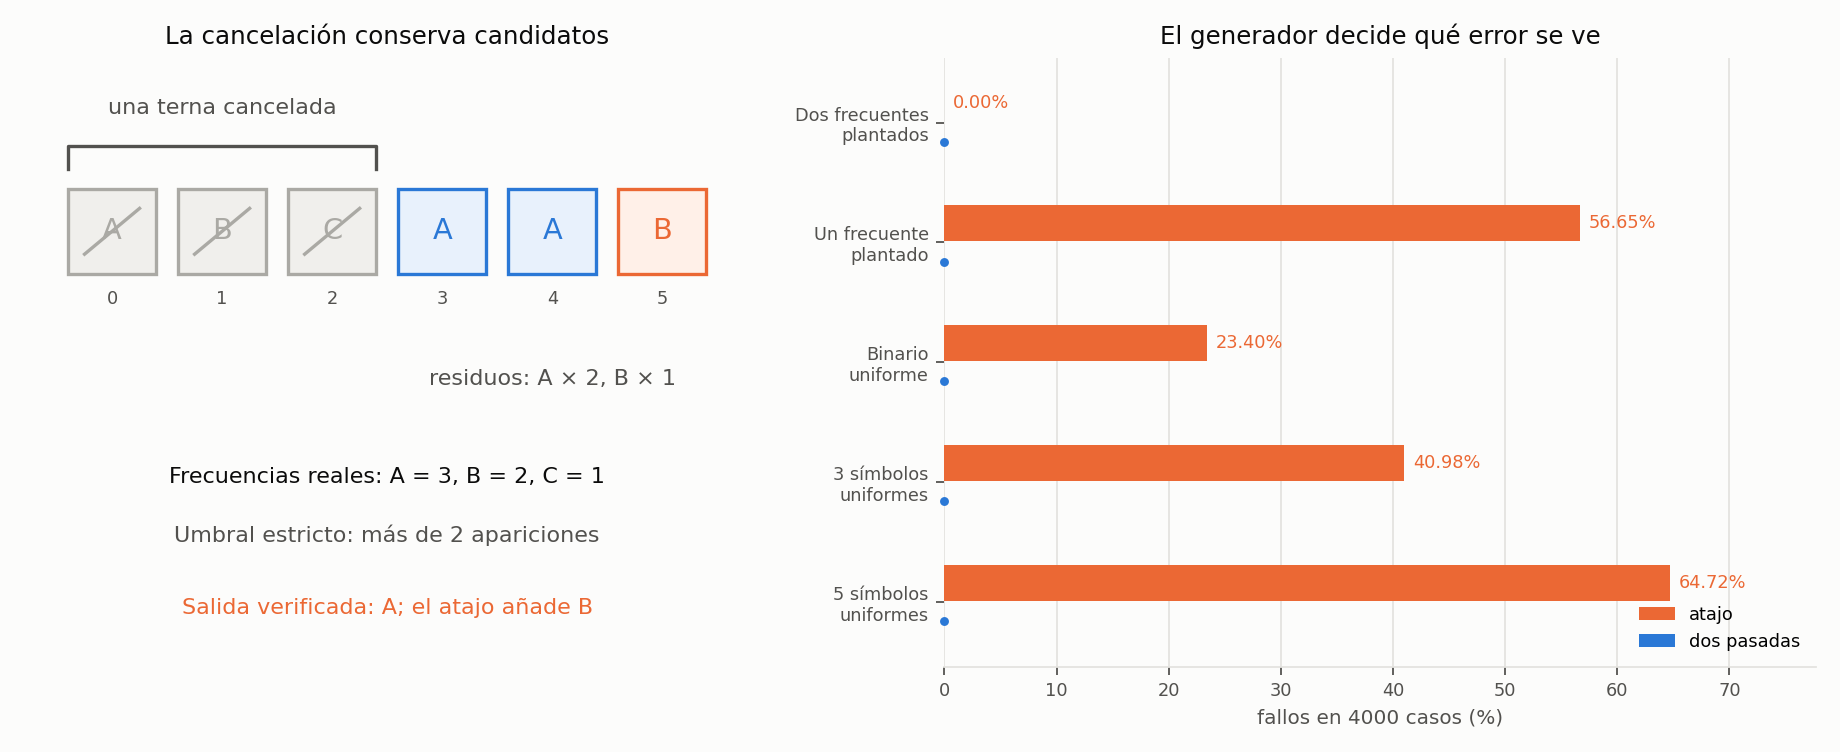

In [10]:
blue, orange = '#2a78d6', '#eb6834'
ink, secondary = '#0b0b0b', '#52514e'
grid, background = '#e4e3df', '#fcfcfb'
fig, (ax_trace, ax_rates) = plt.subplots(1, 2, figsize=(11.5, 4.7), dpi=160,
                                          gridspec_kw={'width_ratios': [1, 1.2]})
fig.patch.set_facecolor(background)

for k, value in enumerate(example):
    cancelled = k < 3
    color = '#aaa9a4' if cancelled else blue if value == 'A' else orange
    fill = '#f0efec' if cancelled else '#e8f1fc' if value == 'A' else '#fff0e8'
    ax_trace.add_patch(Rectangle((k - .4, .8), .8, .65,
                                 facecolor=fill, edgecolor=color, lw=1.5))
    ax_trace.text(k, 1.125, value, ha='center', va='center', color=color, fontsize=13)
    ax_trace.text(k, .57, str(k), ha='center', color=secondary, fontsize=8)
    if cancelled:
        ax_trace.plot([k - .25, k + .25], [.95, 1.3], color=color, lw=1.5)
ax_trace.plot([-.4, -.4, 2.4, 2.4], [1.6, 1.78, 1.78, 1.6], color=secondary)
ax_trace.text(1, 2.02, 'una terna cancelada', ha='center', color=secondary, fontsize=10)
ax_trace.text(4, -.05, 'residuos: A × 2, B × 1', ha='center', color=secondary, fontsize=10)
ax_trace.text(2.5, -.8, 'Frecuencias reales: A = 3, B = 2, C = 1',
              ha='center', color=ink, fontsize=10)
ax_trace.text(2.5, -1.25, 'Umbral estricto: más de 2 apariciones',
              ha='center', color=secondary, fontsize=10)
ax_trace.text(2.5, -1.8, 'Salida verificada: A; el atajo añade B',
              ha='center', color=orange, fontsize=10)
ax_trace.set_title('La cancelación conserva candidatos', color=ink, fontsize=11)
ax_trace.set_xlim(-.8, 5.8)
ax_trace.set_ylim(-2.2, 2.45)
ax_trace.axis('off')

labels = ['Dos frecuentes\nplantados', 'Un frecuente\nplantado', 'Binario\nuniforme',
          '3 símbolos\nuniformes', '5 símbolos\nuniformes']
rates = [100 * r['shortcut'] / r['cases'] for r in experiment_records]
ys = list(range(len(labels)))
ax_rates.barh([y - .16 for y in ys], rates, height=.3, color=orange, label='atajo')
ax_rates.barh([y + .16 for y in ys], [0] * len(ys), height=.3,
              color=blue, label='dos pasadas')
for y, rate in zip(ys, rates):
    ax_rates.text(rate + .8, y - .16, f'{rate:.2f}%', va='center', color=orange, fontsize=8)
    ax_rates.plot(0, y + .16, 'o', color=blue, ms=3, clip_on=False)
ax_rates.set_yticks(ys, labels=labels)
ax_rates.invert_yaxis()
ax_rates.set_xlim(0, max(rates) + 13)
ax_rates.set_xlabel('fallos en 4000 casos (%)', color=secondary, fontsize=9)
ax_rates.set_title('El generador decide qué error se ve', color=ink, fontsize=11)
ax_rates.set_facecolor(background)
ax_rates.grid(axis='x', color=grid, lw=.8)
ax_rates.set_axisbelow(True)
for side in ['top', 'right', 'left']:
    ax_rates.spines[side].set_visible(False)
ax_rates.spines['bottom'].set_color(grid)
ax_rates.tick_params(colors=secondary, labelsize=8)
ax_rates.legend(frameon=False, fontsize=8, loc='lower right')
fig.tight_layout(w_pad=2)
fig.savefig('ejercicio-08.png', facecolor=background)
plt.close(fig)
display(Image(filename='ejercicio-08.png'))


## 6. Conclusiones

La partición del prefijo en ternas de valores distintos más copias residuales
es inductiva y garantiza que ningún valor frecuente se pierde. La segunda pasada
descarta falsos positivos. El algoritmo es lineal y usa memoria constante.

El atajo falla ya con `AAB`, así que las pruebas binarias sí lo detectan.
Garantizar dos frecuentes plantados lo hace correcto en toda la familia y oculta
el error. Plantar solo uno no basta: deben probarse también entradas con cero
o una respuesta verdadera. Las pruebas comprueban las familias enumeradas;
las demostraciones del informe cubren cualquier largo.


In [11]:
print('Todas las comprobaciones finalizaron correctamente.')
print(f'Arreglos exhaustivos: {exhaustive_cases}; prefijos: {prefixes}')
print(f'Casos binarios adicionales: {binary_cases}')
print(f'Experimento: {sum(r["cases"] for r in experiment_records)} casos con semillas fijas')
print('Contraejemplo mínimo: AAB; el atajo añade B.')
print('Figura guardada en ejercicio-08.png')


Todas las comprobaciones finalizaron correctamente.
Arreglos exhaustivos: 21845; prefijos: 167481
Casos binarios adicionales: 2047
Experimento: 20000 casos con semillas fijas
Contraejemplo mínimo: AAB; el atajo añade B.
Figura guardada en ejercicio-08.png
